# 06 · EDA univariado

**Fase CRISP-DM:** 2. Entendimiento de los datos

**Objetivo:** describir la distribución de cada variable **por separado**, para decidir transformaciones (log, agrupación de categorías raras) y entender las escalas antes de relacionarlas en el notebook 07.

**Regla de oro:** cada variable se describe en su **unidad natural**. El precio es por platillo del menú, el ticket por mesa, las visitas por comensal. Mezclar unidades (por ejemplo, promediar precios sobre líneas pedidas) cambia la pregunta sin avisar.

**Entradas:** tablas del contrato de la corrida base (sin verdad oculta).
**Salidas:** figuras en `reports/figures/06_*.png` y decisiones de transformación para el notebook 10.

> Este notebook solo narra el algoritmo. La lógica vive en `src/puzzle_recsys`.

## Configuración y carga

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from puzzle_recsys.config import load_paths, load_simulation
from puzzle_recsys.eda.plots import plot_distribution, plot_frequencies
from puzzle_recsys.eda.univariate import describe_numeric, frequency_table, ticket_per_session
from puzzle_recsys.repository.parquet_repo import ParquetRepository, run_id_for

paths, sim = load_paths(), load_simulation()
repo = ParquetRepository(paths.synthetic / run_id_for(sim.run_name, sim.seed))
t = {n: repo.read_table(n) for n in ["restaurants", "menu_items", "diners", "diner_profiles",
                                     "dining_sessions", "guests", "order_items", "dish_ratings", "visit_ratings"]}
tz = sim.calendar["timezone"]
figs = paths.figures
figs.mkdir(parents=True, exist_ok=True)
r, mi, s, g, oi = t["restaurants"], t["menu_items"], t["dining_sessions"], t["guests"], t["order_items"]

## 1. Variables numéricas

Cada fila es una variable con su unidad. Columnas clave:

- **asimetria** > 1: cola derecha fuerte; la media deja de ser representativa.
- **asimetria_log**: la asimetría tras aplicar logaritmo. Si queda cerca de 0, el log es la transformación natural.
- **p_normalidad**: prueba de D'Agostino-Pearson sobre una muestra de 5,000. Con millones de filas cualquier prueba rechaza por diferencias irrelevantes; muestrear la mantiene interpretable.

In [2]:
ticket = ticket_per_session(oi)
registered = g.dropna(subset=["diner_id"]).merge(s[["session_id", "opened_at"]], on="session_id")
registered = registered.sort_values(["diner_id", "opened_at"])
gaps = registered.groupby("diner_id")["opened_at"].diff().dt.total_seconds() / 86_400

variables = {
    "precio del platillo (MXN, por platillo del menú)": mi["price_cents"] / 100,
    "tamaño del menú (platillos, por restaurante)": mi.loc[mi["archived_at"].isna()].groupby("restaurant_id").size(),
    "mesas en el año (por restaurante)": s.groupby("restaurant_id").size(),
    "personas en la mesa (pax, por mesa)": s["pax"],
    "ticket (MXN, por mesa)": ticket,
    "ticket por persona (MXN, por mesa)": ticket / s.set_index("session_id")["pax"].reindex(ticket.index),
    "líneas pedidas (por invitado con pedido)": oi.dropna(subset=["guest_id"]).groupby("guest_id").size(),
    "visitas en el año (por comensal registrado)": registered.groupby("diner_id").size(),
    "días entre visitas (por par de visitas)": gaps[gaps > 0],
}
summary = pd.DataFrame({k: describe_numeric(v) for k, v in variables.items()}).T
summary.round(2)

,n,media,mediana,desv_est,p01,p99,asimetria,curtosis,asimetria_log,p_normalidad
"precio del platillo (MXN, por platillo del menú)",36115.0,107.77,90.00,77.00,25.00,355.00,4.39,43.90,0.17,0.0
"tamaño del menú (platillos, por restaurante)",1500.0,19.90,19.00,6.32,8.00,37.00,0.50,-0.06,-0.33,0.0
mesas en el año (por restaurante),1498.0,343.46,234.00,346.84,5.00,1581.09,2.07,6.14,-0.86,0.0
"personas en la mesa (pax, por mesa)",514510.0,2.88,2.00,1.66,1.00,6.00,3.65,42.29,-0.15,0.0
"ticket (MXN, por mesa)",513139.0,703.02,590.00,519.89,79.00,2310.00,3.42,35.31,-0.44,0.0
"ticket por persona (MXN, por mesa)",513139.0,243.38,227.40,110.59,62.50,610.00,2.28,14.85,-0.41,0.0
líneas pedidas (por invitado con pedido),1448465.0,2.26,2.00,0.87,1.00,4.00,0.38,-0.15,-0.50,0.0
visitas en el año (por comensal registrado),20221.0,37.09,31.00,24.95,6.00,126.00,2.10,7.62,-0.16,0.0
días entre visitas (por par de visitas),729761.0,9.43,5.81,11.64,0.26,56.08,3.65,24.20,-0.28,0.0


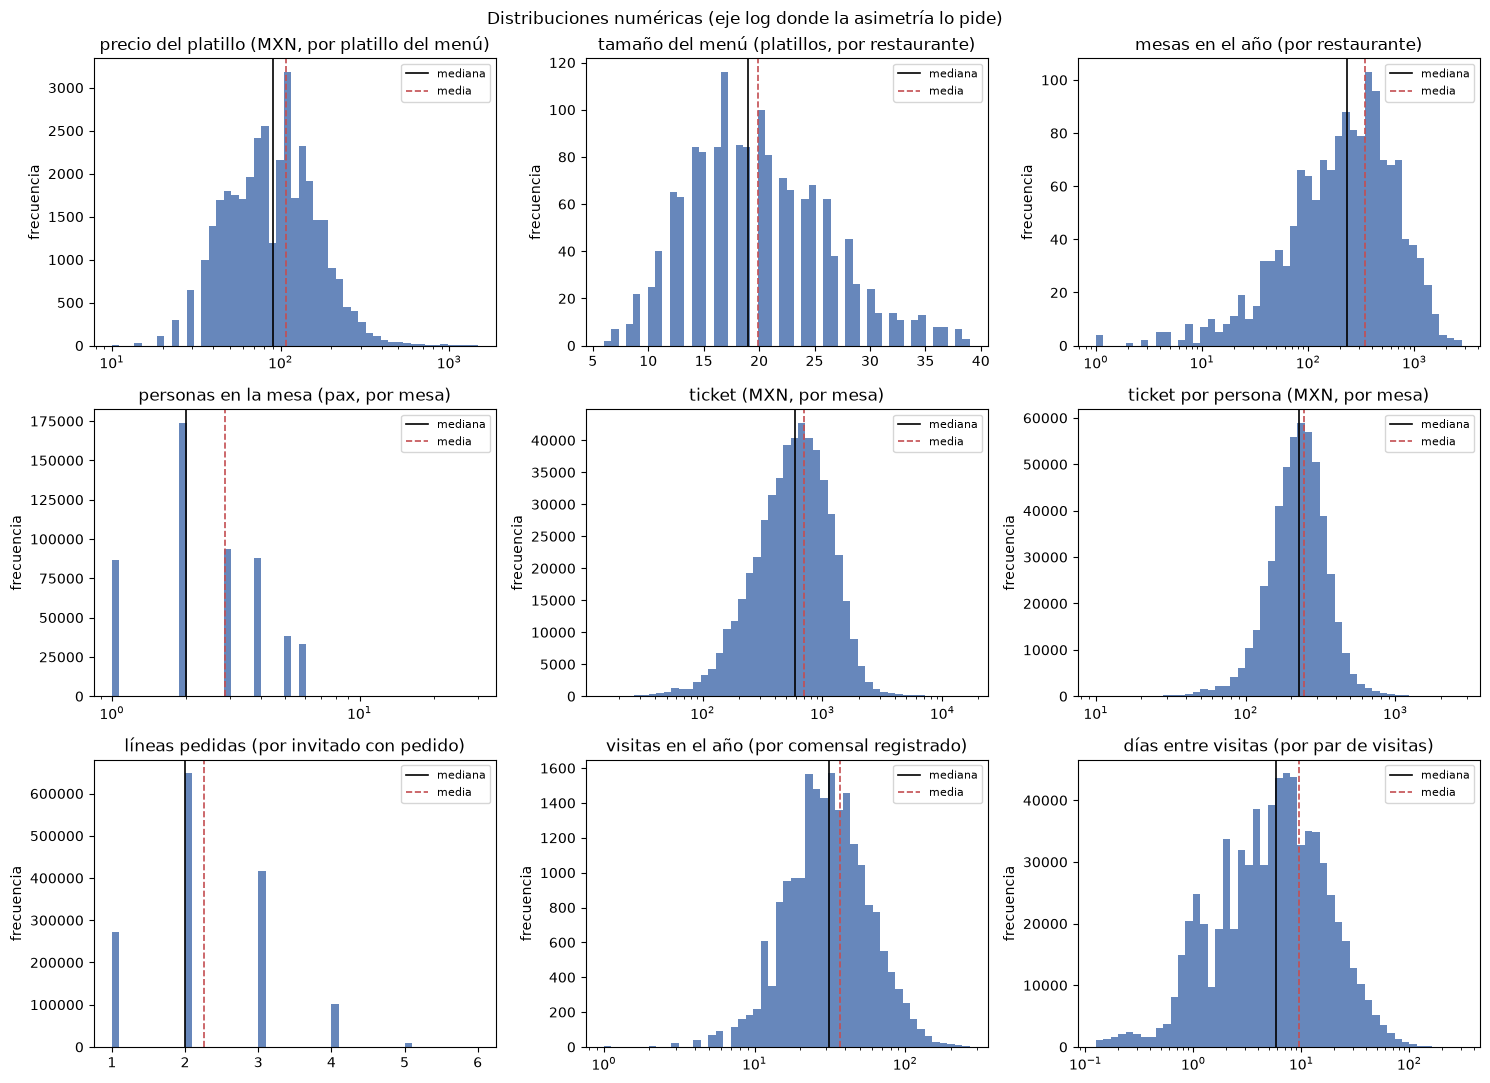

In [3]:
log_scale = {k: row["asimetria"] > 1 and row["asimetria_log"] < row["asimetria"] / 2 for k, row in summary.iterrows()}
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, (name, values) in zip(axes.ravel(), variables.items()):
    plot_distribution(values, title=name, log=bool(log_scale[name]), ax=ax)
fig.suptitle("Distribuciones numéricas (eje log donde la asimetría lo pide)")
fig.tight_layout()
fig.savefig(figs / "06_numericas.png", dpi=150)

## 2. Variables categóricas y ordinales

Frecuencias con los **faltantes explícitos** y la cola larga agrupada en "otras", para que las categorías raras no se escondan ni dominen la gráfica.

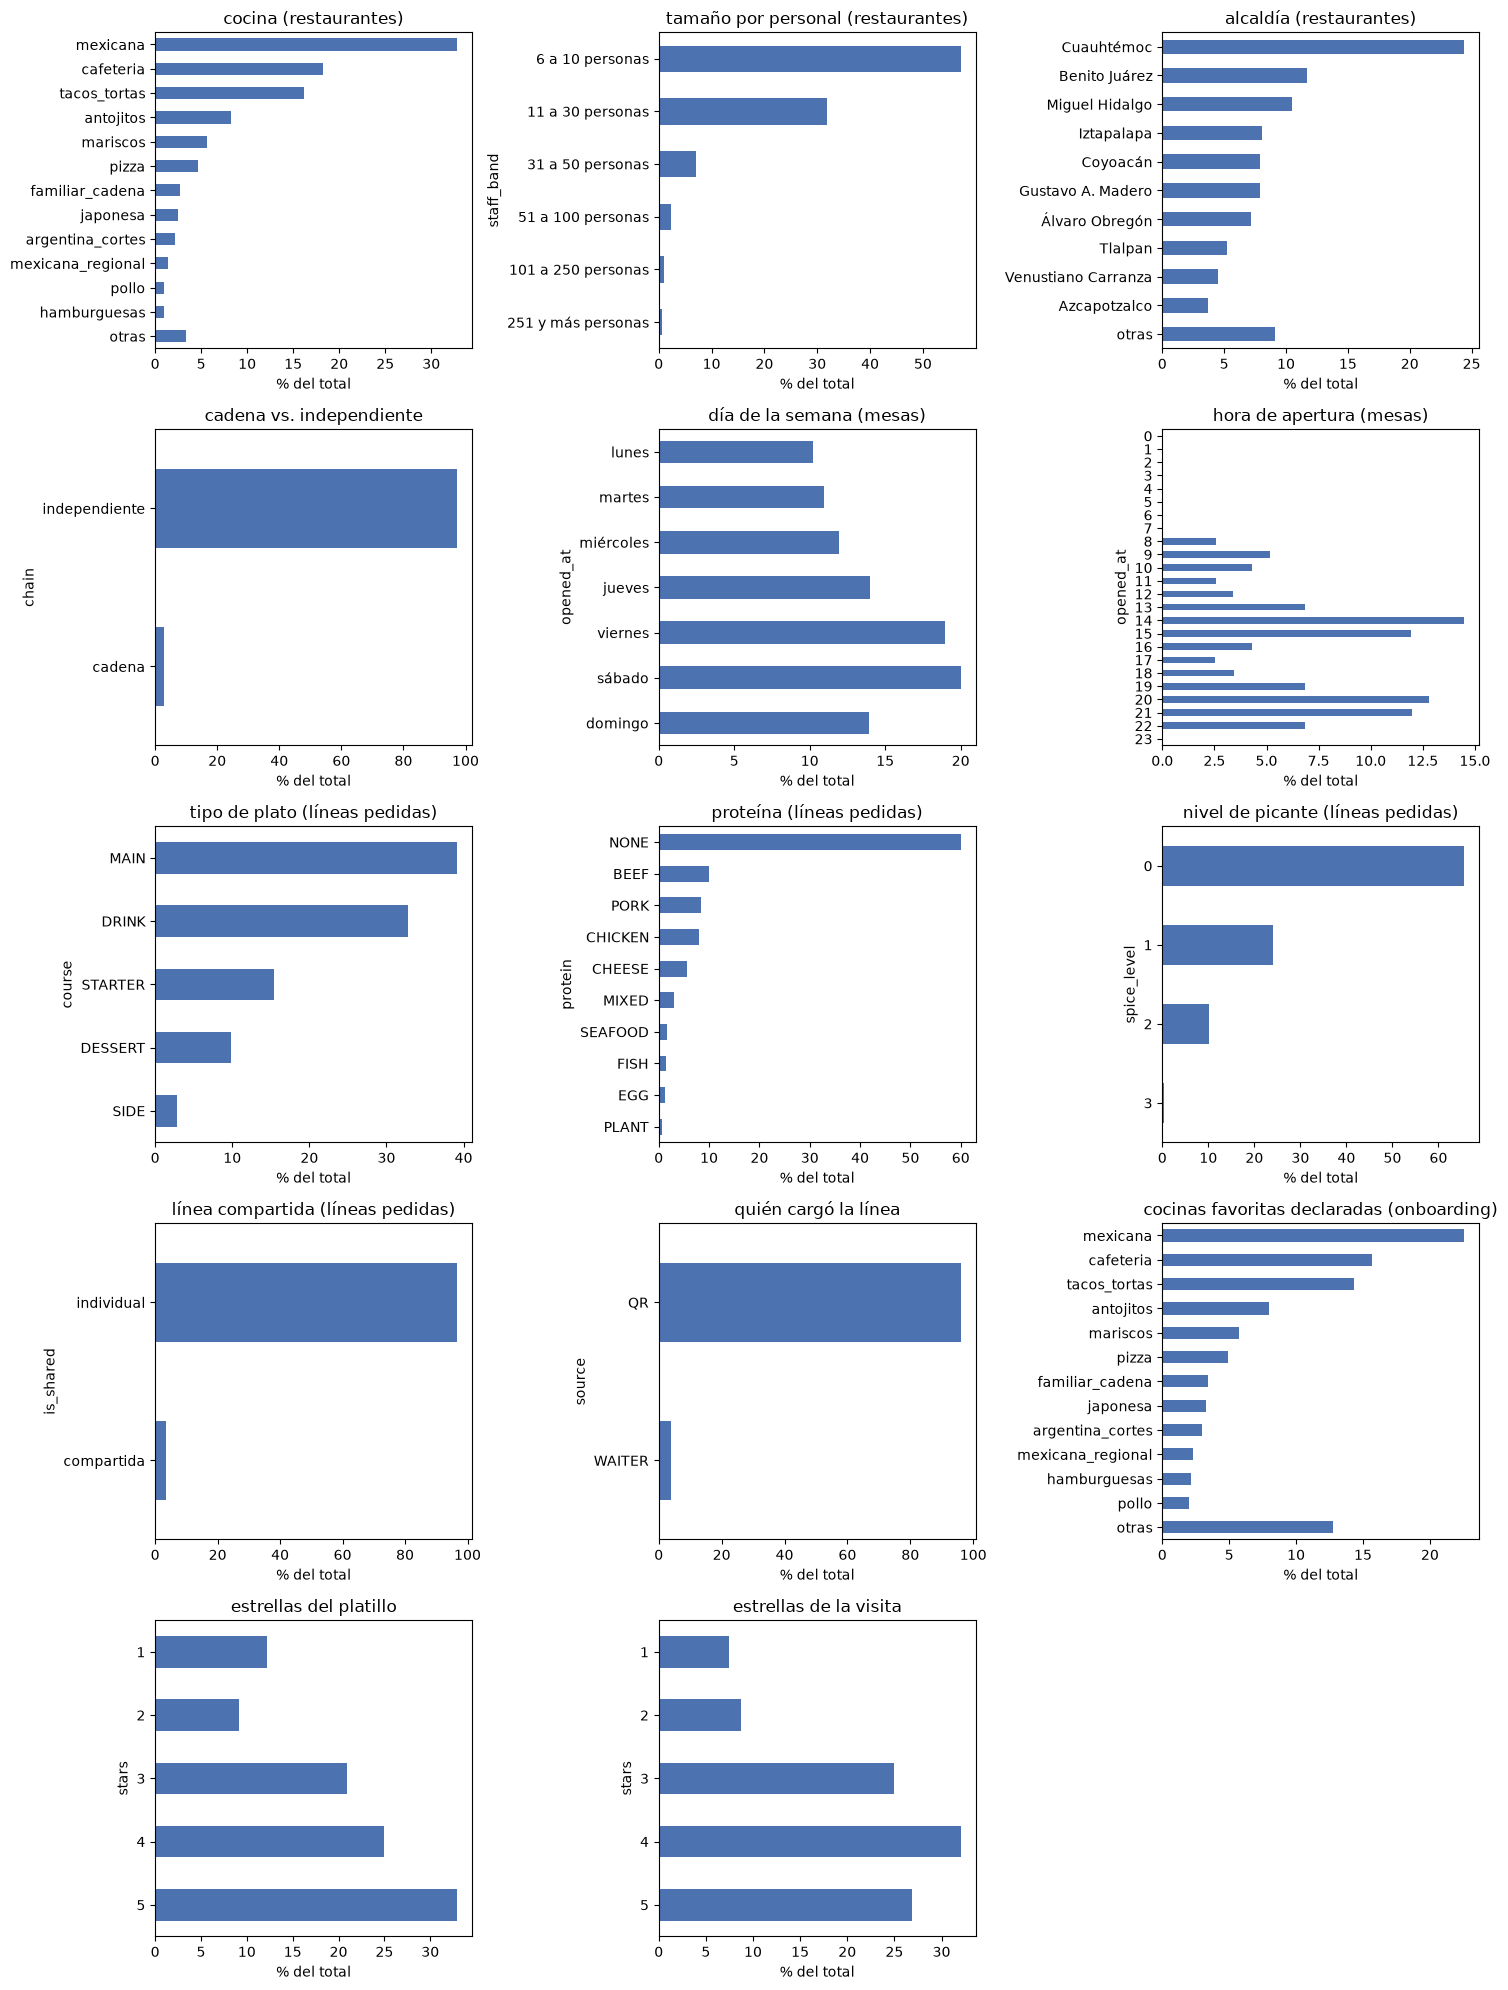

In [4]:
dias = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
opened_local = s["opened_at"].dt.tz_convert(tz)
lines = oi.merge(mi[["menu_item_id", "course", "protein", "spice_level"]], on="menu_item_id")
favorites = t["diner_profiles"]["favorite_cuisines"].explode().dropna()

categorical = {
    "cocina (restaurantes)": frequency_table(r["cuisine_pred"], top=12),
    "tamaño por personal (restaurantes)": frequency_table(r["staff_band"]),
    "alcaldía (restaurantes)": frequency_table(r["alcaldia"], top=10),
    "cadena vs. independiente": frequency_table(r["chain"].notna().map({True: "cadena", False: "independiente"})),
    "día de la semana (mesas)": frequency_table(opened_local.dt.day_of_week.map(dict(enumerate(dias))), order=dias),
    "hora de apertura (mesas)": frequency_table(opened_local.dt.hour, order=list(range(24))),
    "tipo de plato (líneas pedidas)": frequency_table(lines["course"]),
    "proteína (líneas pedidas)": frequency_table(lines["protein"], top=10),
    "nivel de picante (líneas pedidas)": frequency_table(lines["spice_level"], order=[0, 1, 2, 3]),
    "línea compartida (líneas pedidas)": frequency_table(oi["is_shared"].map({True: "compartida", False: "individual"})),
    "quién cargó la línea": frequency_table(oi["source"]),
    "cocinas favoritas declaradas (onboarding)": frequency_table(favorites, top=12),
    "estrellas del platillo": frequency_table(t["dish_ratings"]["stars"], order=[1, 2, 3, 4, 5]),
    "estrellas de la visita": frequency_table(t["visit_ratings"]["stars"], order=[1, 2, 3, 4, 5]),
}
fig, axes = plt.subplots(5, 3, figsize=(15, 20))
for ax, (name, table) in zip(axes.ravel(), categorical.items()):
    plot_frequencies(table, title=name, ax=ax)
axes.ravel()[-1].set_axis_off()
fig.tight_layout()
fig.savefig(figs / "06_categoricas.png", dpi=150)

Tablas de las variables que más pesan en el modelo:

In [5]:
for name in ["cocina (restaurantes)", "tipo de plato (líneas pedidas)", "día de la semana (mesas)",
             "estrellas del platillo", "estrellas de la visita"]:
    display(categorical[name].round(2).rename_axis(name))

,n,%,% acumulado
cocina (restaurantes),,,
mexicana,492,32.80,32.80
cafeteria,274,18.27,51.07
tacos_tortas,243,16.20,67.27
antojitos,124,8.27,75.53
mariscos,84,5.60,81.13
pizza,70,4.67,85.80
familiar_cadena,41,2.73,88.53
japonesa,38,2.53,91.07
argentina_cortes,33,2.20,93.27


,n,%,% acumulado
tipo de plato (líneas pedidas),,,
MAIN,1335025,39.15,39.15
DRINK,1115996,32.73,71.88
STARTER,527264,15.46,87.34
DESSERT,333388,9.78,97.12
SIDE,98262,2.88,100.00


,n,%,% acumulado
día de la semana (mesas),,,
lunes,52709,10.24,10.24
martes,56247,10.93,21.18
miércoles,61565,11.97,33.14
jueves,71884,13.97,47.11
viernes,97535,18.96,66.07
sábado,102870,19.99,86.06
domingo,71700,13.94,100.00


,n,%,% acumulado
estrellas del platillo,,,
1,51292,12.14,12.14
2,38478,9.11,21.25
3,88149,20.87,42.12
4,105447,24.96,67.08
5,139049,32.92,100.00


,n,%,% acumulado
estrellas de la visita,,,
1,22761,7.44,7.44
2,26661,8.72,16.16
3,76243,24.93,41.09
4,97945,32.02,73.11
5,82248,26.89,100.00


## 3. Hallazgos para el diseño del ranking

Para LambdaRank cada **consulta** es una visita × tipo de plato, y los **candidatos** son los platillos de ese tipo en el menú. Interesa cuántos candidatos hay por consulta (dificultad del ranking) y cuántos positivos (pedidos) trae cada una.

In [6]:
menu_by_course = mi.loc[mi["archived_at"].isna()].groupby(["restaurant_id", "course"]).size()
queries = lines.dropna(subset=["guest_id"]).groupby(["guest_id", "course"]).size()
pd.DataFrame({
    "candidatos por consulta (platillos del tipo en el menú)": describe_numeric(menu_by_course),
    "positivos por consulta (líneas del invitado en ese tipo)": describe_numeric(queries),
}).T[["n", "media", "mediana", "p01", "p99", "asimetria"]].round(2)

,n,media,mediana,p01,p99,asimetria
candidatos por consulta (platillos del tipo en el menú),6557.0,4.55,4.0,1.0,12.0,0.76
positivos por consulta (líneas del invitado en ese tipo),3231513.0,1.01,1.0,1.0,2.0,8.65


## Conclusiones

### Variables numéricas: cola derecha y el log como transformación natural

| Variable (unidad) | Mediana | Asimetría | Asimetría tras log |
|---|---|---|---|
| Precio del platillo (por platillo) | $90 | 4.4 | 0.2 |
| Ticket (por mesa) | $590 | 3.4 | -0.4 |
| Ticket por persona (por mesa) | $227 | 2.3 | -0.4 |
| Visitas en el año (por comensal) | 31 | 2.1 | -0.2 |
| Días entre visitas (por par) | 5.8 | 3.7 | -0.3 |
| Mesas en el año (por restaurante) | 234 | 2.1 | -0.9 |

- Precio, ticket, frecuencia y tiempo entre visitas son **asimétricos a la derecha**: la media queda arriba de la mediana (precio: $108 contra $90) y **la mediana es el resumen correcto**. Con logaritmo quedan casi simétricos.
- **Ninguna variable es normal**, ni siquiera tras el log (p < 0.001 con muestras de 5,000). Por eso el notebook 07 usa pruebas **no paramétricas** (Spearman, Kruskal-Wallis, chi²).
- **Mesas por restaurante** es la excepción: el log sobrecorrige (-0.9) porque hay una cola de restaurantes con muy poca historia (p01 = 5 mesas al año). Es el problema de **arranque en frío**: para esos lugares la popularidad propia no es confiable y hace falta el respaldo jerárquico (popularidad por cocina).
- **Tamaño de mesa:** mediana 2 personas; la cola (asimetría 3.7) son las mesas gigantes sembradas como ruido (notebook 05).

### Variables categóricas

- **Cocina:** mexicana 33 %, cafetería 18 %, tacos y tortas 16 %. Las 12 principales cubren el 97 %; las cocinas con menos de 1 % se agrupan en "otras" antes del one-hot (notebook 10), para no crear columnas casi vacías.
- **Cuándo:** viernes y sábado concentran el 39 % de las mesas; picos a las 14–15 h (comida, 26 %) y 20–21 h (cena, 25 %).
- **Qué se pide:** plato fuerte 39 %, bebida 33 %, entrada 16 %, postre 10 %, guarnición 3 %. La guarnición tendrá **pocos positivos**: sus métricas se reportan aparte, sin mezclarlas con el promedio global.
- **Proteína:** el 60 % de las líneas es "NONE" porque bebidas y postres no llevan proteína. La proteína solo tiene sentido **dentro del tipo de plato** (interacción a revisar en el notebook 07).
- **Picante:** 66 % nivel 0 y solo 0.3 % nivel 3.
- **Compartir:** solo el 3.4 % de las **líneas** es compartida, aunque el 22 % de las **mesas** comparte algo (notebook 04). Es el mismo fenómeno medido en dos unidades: por eso importa declarar la unidad.
- **Estrellas del platillo en forma de J:** 12 % de una estrella y 33 % de cinco. Es la huella del faltante MNAR: califica sobre todo quien quedó en un extremo. Las estrellas de la visita son más centrales (4 estrellas = 32 %).

### Qué implica para el ranking (decisiones que pasan al modelado)

- **Consultas chicas:** cada consulta (una persona × tipo de plato) tiene una **mediana de 4 candidatos** (p99 = 12). Las métricas se miden en el top 3 (NDCG@3, HitRate@3); un top 10 sería trivial porque casi siempre incluye todo el menú del tipo.
- **Relevancia binaria:** casi siempre hay **1 solo positivo** por consulta (p99 = 2). La etiqueta es "lo pidió / no lo pidió".
- **Transformación:** log en precio, ticket, frecuencias y días entre visitas. Para LightGBM no cambia nada (los árboles solo usan el orden de los valores), pero **sí importa** para la regresión logística de referencia y para leer las gráficas.

### Lo que este EDA destapó

Las figuras mostraron **visitas del mismo comensal separadas por minutos** y **horas sin ninguna mesa**. El primero era un bug real: un acompañante registrado podía estar en dos mesas a la vez. Se corrigió con una agenda global y un test de regresión (notebook 03, corrección 6) y se agregó como chequeo de consistencia al notebook 05. El segundo era un perfil horario incompleto, ahora declarado como supuesto S15. Toda la cadena se volvió a ejecutar y la validación del notebook 04 sigue en banda.

**Pasa al notebook 07:** relaciones entre pares de variables con pruebas no paramétricas.
